<a href="https://colab.research.google.com/github/akshat280706/IP-LABS/blob/main/241080009_akshat_IP_LAB1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Akshat Chauhan
#241080009
#IT

In [ ]:
from google.colab import files
uploaded=files.upload()


Saving for IP.jfif to for IP (1).jfif


In [ ]:
from PIL import Image
from IPython.display import display

img=Image.open("for IP.jfif")
print("Image size: ", img.size)
print("image mode: ", img.mode)

Image size:  (640, 480)
image mode:  RGB


new image is: 


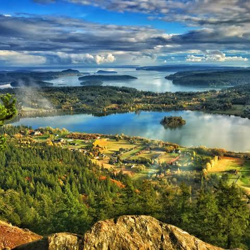

In [ ]:
width,height=img.size

square_size=min(width,height)

left=(width-square_size) // 2
top=(height-square_size) // 2
right=left+square_size
bottom=top+square_size

square_img=img.crop((left,top,right,bottom))

thumbnail=square_img.resize((250,250))
thumbnail.save("thumbnail.png")
print("new image is: ")
display(thumbnail)

og image: 


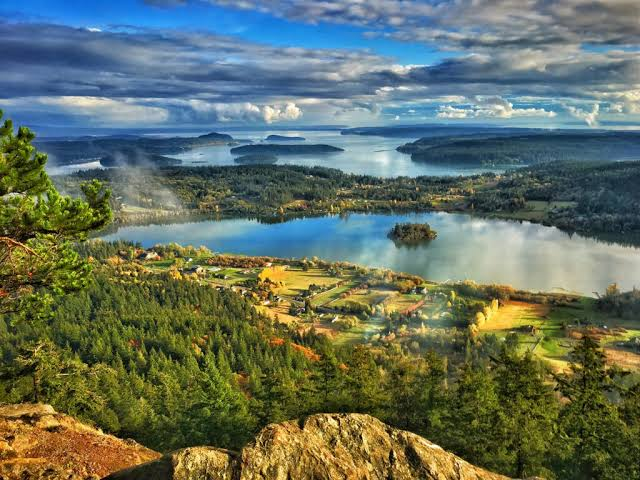



blue scale image: 


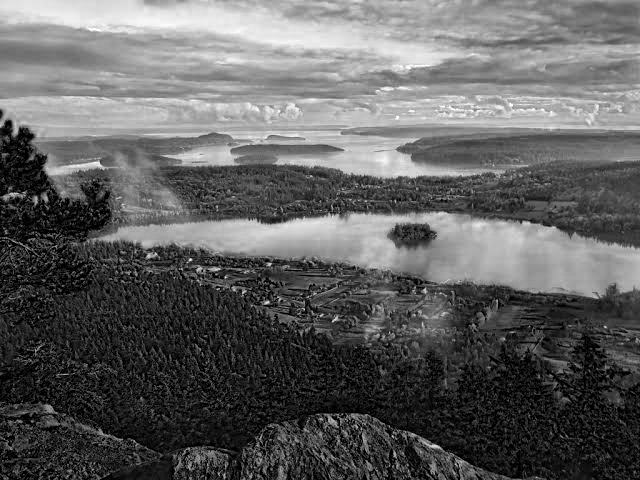



red scale image: 


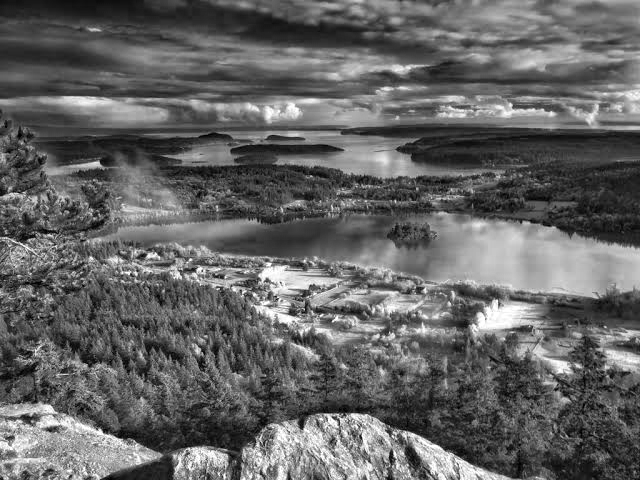



green image: 


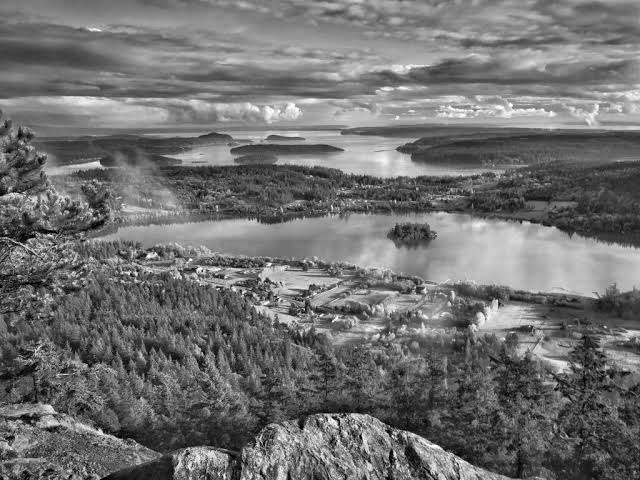



gray scale img: 


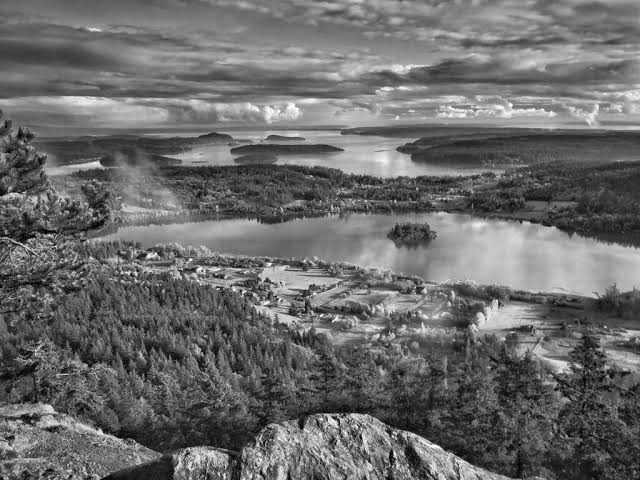

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

img=cv2.imread("for IP.jfif")

B,G,R=cv2.split(img)
gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
print("og image: ")
cv2_imshow(img)
print("\n")

print("blue scale image: ")
cv2_imshow(B)
print("\n")

print("red scale image: ")
cv2_imshow(R)
print("\n")

print("green image: ")
cv2_imshow(G)
print("\n")

print("gray scale img: ")
cv2_imshow(gray)

img flipped horizontally


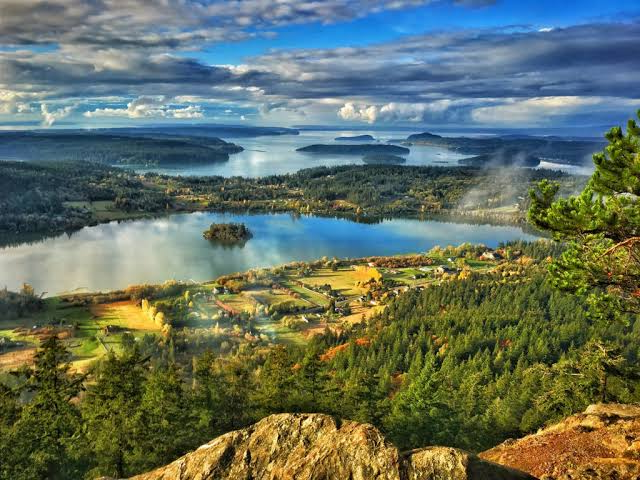

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

def mirror_image(image_path):
    image = cv2.imread(image_path)
    if image is None:
        print("error, img not found")
        return
    height, width = image.shape[:2]

    if width > height:
        result = cv2.flip(image, 1)
        print("img flipped horizontally")
    elif height > width:
        result = cv2.flip(image, 0)
        print("img flipped vertically.")
    else:
        result = image.copy()
        print("sqaure img, so no flip applied")

    cv2_imshow(result)
    cv2.imwrite("mirrored_image.jpg", result)
mirror_image("for IP.jfif")

Original dimensions: 640 * 480
Aspect ratio: 1.3333333333333333
New dimensions: 500 * 375


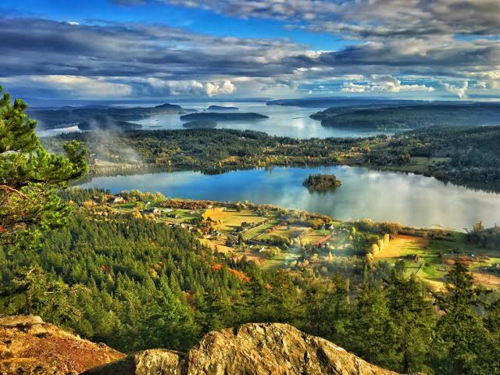

In [ ]:
from PIL import Image

def resize_image(image_path):
    image = Image.open(image_path)

    original_width, original_height = image.size
    aspect_ratio = original_width / original_height

    new_width = 500

    new_height = int(new_width / aspect_ratio)
    resized_image = image.resize((new_width, new_height))

    if resized_image.mode not in ("RGB", "RGBA"):
        resized_image = resized_image.convert("RGB")

    resized_image.save("resized_image.png")

    print("Original dimensions:", original_width, "*", original_height)
    print("Aspect ratio:", aspect_ratio)
    print("New dimensions:", new_width, "*", new_height)
    display(resized_image)

resize_image("for IP.jfif")

Original image:


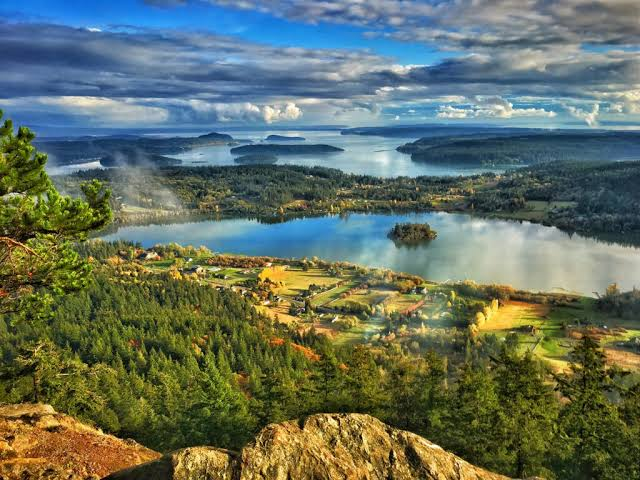


Contrast and vignette:


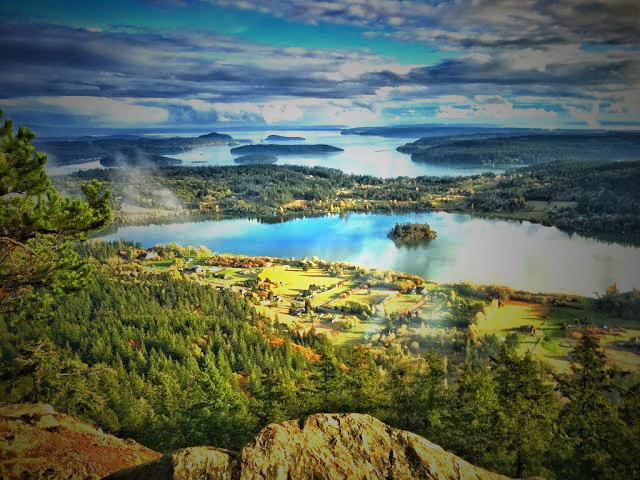

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread("for IP.jfif")

if image is None:
    print("error, img not found.")
else:
    contrast_image = cv2.convertScaleAbs(image, alpha=1.5, beta=0)

    height, width = image.shape[:2]
    y, x = np.ogrid[:height, :width]
    distance = np.sqrt((x - width / 2)**2 + (y - height / 2)**2)
    mask = 1 - 0.7 * distance / distance.max()
    mask = np.clip(mask, 0, 1)

    result = (contrast_image * mask[:, :, np.newaxis]).astype(np.uint8)

    print("Original image:")
    cv2_imshow(image)

    print("\nContrast and vignette:")
    cv2_imshow(result)
    cv2.imwrite("contrast_vignette.png", result)